# CDMA 64 用户实验：Python 参考实现

代码整理自《CDMA_64用户实验指导书》第 6 节。运行环境：Python 3.10+，依赖 `numpy`。

In [ ]:
import numpy as np

NUM_USERS = 64
CODE_LENGTH = 64


def generate_walsh_codes(n=64):
    if n < 1 or (n & (n - 1)) != 0:
        raise ValueError("n must be a positive power of two")
    H = np.array([[1]], dtype=np.int64)
    while H.shape[0] < n:
        H = np.block([[H, H], [H, -H]])
    return H


def ascii_to_bits(text):
    raw = text.encode("ascii")
    return np.unpackbits(np.frombuffer(raw, dtype=np.uint8))


def bits_to_ascii(bits):
    bits = np.asarray(bits, dtype=np.uint8)
    if len(bits) % 8 != 0:
        raise ValueError("bits length must be multiple of 8")
    return np.packbits(bits).tobytes().decode("ascii")


def spread_bits(bits, code):
    bipolar = 2 * np.asarray(bits, dtype=np.int64) - 1
    return bipolar[:, None] * code[None, :]


def combine_signals(spread_signals):
    return np.sum(spread_signals, axis=0)


def decode_user(combined_signal, code):
    correlation = combined_signal @ code / len(code)
    bits = (correlation > 0).astype(np.uint8)
    return bits, correlation


def main():
    H = generate_walsh_codes(CODE_LENGTH)
    print("Walsh matrix shape:", H.shape)
    print("First 8 user codes:\n", H[:8])
    # 验证正交性：理论上 H x H.T 应等于 64I。
    expected = CODE_LENGTH * np.eye(NUM_USERS, dtype=np.int64)
    gram_matrix = H @ H.T
    orthogonality_verified = np.array_equal(gram_matrix, expected)
    # 计算实际结果与理论结果之间的最大误差；0 表示完全正交。
    maximum_orthogonality_error = np.max(np.abs(gram_matrix - expected))
    # 输出验证结果，便于实验验收和报告截图。
    print("Orthogonality verified:", orthogonality_verified)
    print("Maximum orthogonality error:", maximum_orthogonality_error)
    # 验证失败时立即终止，避免使用错误的 Walsh 码继续实验。
    assert orthogonality_verified

    messages = [chr(ord("A") + i % 26) for i in range(NUM_USERS)]
    spread_signals = [
        spread_bits(ascii_to_bits(messages[i]), H[i])
        for i in range(NUM_USERS)
    ]
    combined_signal = combine_signals(spread_signals)
    print("Combined signal shape:", combined_signal.shape)
    print("First bit composite chips:\n", combined_signal[0])

    correct = 0
    recovered = []
    for i in range(NUM_USERS):
        bits, correlation = decode_user(combined_signal, H[i])
        text = bits_to_ascii(bits)
        recovered.append(text)
        is_correct = text == messages[i]
        correct += int(is_correct)
        print(
            f"User {i + 1:02d}: TX={messages[i]} "
            f"RX={text} correct={is_correct}"
        )

    print(f"Recovered correctly: {correct}/{NUM_USERS}")
    print(f"Accuracy: {correct / NUM_USERS:.2%}")
    assert recovered == messages


if __name__ == "__main__":
    main()

Walsh matrix shape: (64, 64)
First 8 user codes:
 [[ 1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
   1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
   1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1]
 [ 1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1
   1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1
   1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1  1 -1]
 [ 1  1 -1 -1  1  1 -1 -1  1  1 -1 -1  1  1 -1 -1  1  1 -1 -1  1  1 -1 -1
   1  1 -1 -1  1  1 -1 -1  1  1 -1 -1  1  1 -1 -1  1  1 -1 -1  1  1 -1 -1
   1  1 -1 -1  1  1 -1 -1  1  1 -1 -1  1  1 -1 -1]
 [ 1 -1 -1  1  1 -1 -1  1  1 -1 -1  1  1 -1 -1  1  1 -1 -1  1  1 -1 -1  1
   1 -1 -1  1  1 -1 -1  1  1 -1 -1  1  1 -1 -1  1  1 -1 -1  1  1 -1 -1  1
   1 -1 -1  1  1 -1 -1  1  1 -1 -1  1  1 -1 -1  1]
 [ 1  1  1  1 -1 -1 -1 -1  1  1  1  1 -1 -1 -1 -1  1  1  1  1 -1 -1 -1 -1
   1  1  1  1 -1 -1 -1 -1  1  1  1  1 -1 -1 -1 -1  1  1  1  1 -1 -1 -1 -1
   1  

## 选做：AWGN 噪声与误码率实验

每个用户发送 1000 个 ASCII 字符，随机种子为 42，测试噪声标准差 $\sigma\in\{0,2,4,8,16\}$。

In [2]:
# 导入选做的 AWGN 噪声与 BER 实验函数。
from cdma_64 import run_noise_ber_experiment

# 每用户发送 1000 个字符，固定随机种子 42，
# 分别统计噪声标准差为 0、2、4、8、16 时的 BER。
ber_results = run_noise_ber_experiment(
    num_chars=1000,
    noise_stds=(0, 2, 4, 8, 16),
    seed=42,
    output_dir="results",
)
ber_results


AWGN BER experiment
Characters per user: 1000
Random seed: 42
Total transmitted bits: 512000
noise_std= 0: bit_errors=     0, BER=0.00000000
noise_std= 2: bit_errors=    18, BER=0.00003516
noise_std= 4: bit_errors= 11667, BER=0.02278711
noise_std= 8: bit_errors= 81279, BER=0.15874805
noise_std=16: bit_errors=157273, BER=0.30717383
BER data saved to: results\ber_results.csv
BER curve saved to: results\ber_curve.png


<IPython.core.display.Image object>


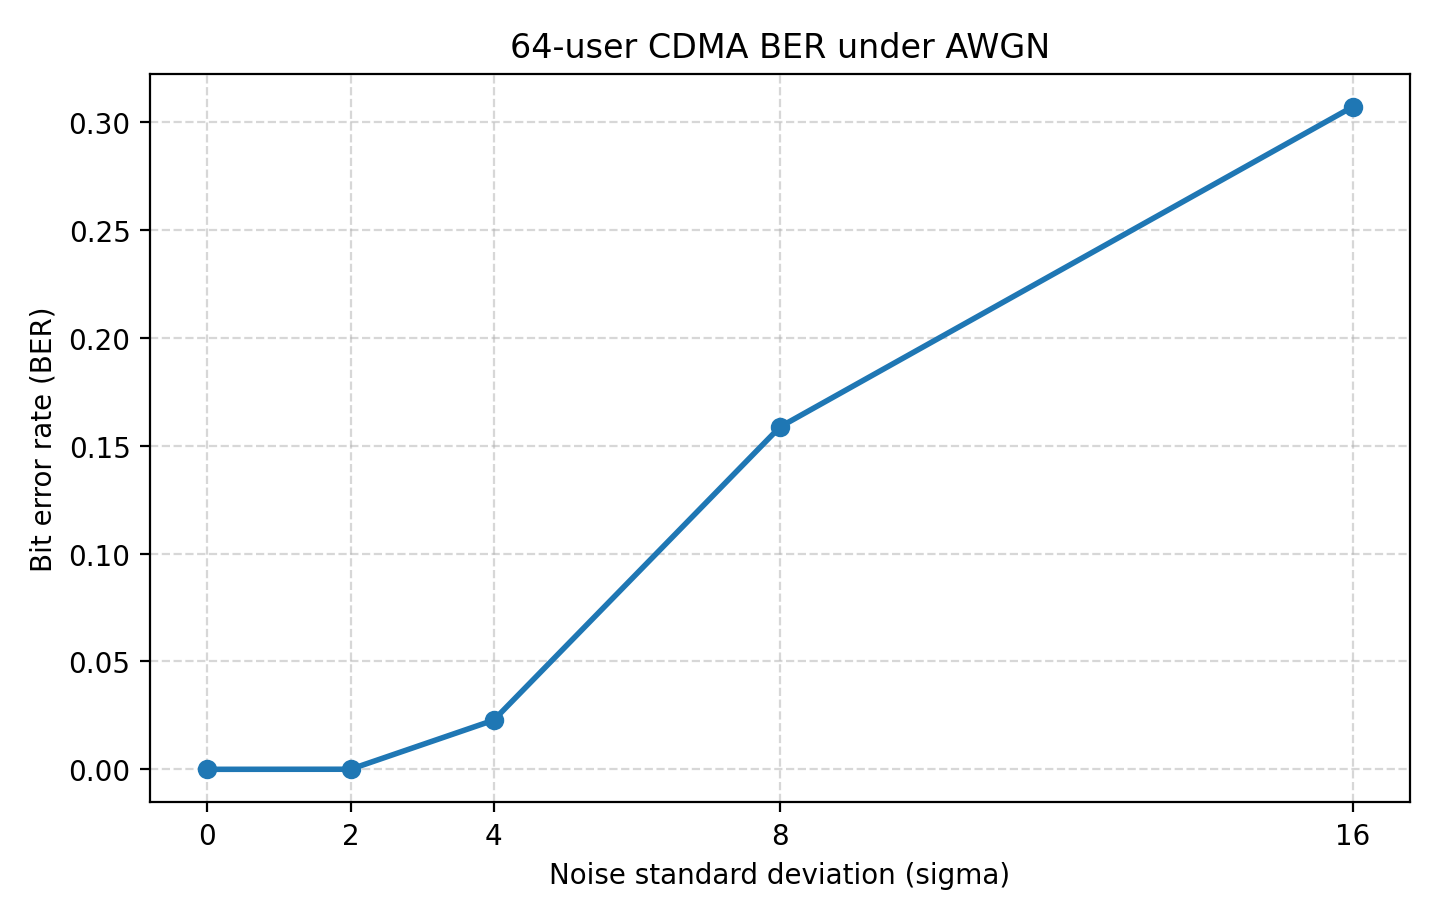

In [3]:
# 在 Notebook 中显示选做实验生成的 BER 曲线。
from IPython.display import Image, display

display(Image(filename="results/ber_curve.png"))